In [12]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

1. Loading data

In [3]:
# loading data
df = pd.read_csv("../data/Autoimmune_Disorder_10k_with_All_Disorders.csv")

In [4]:
df.head()

,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,...,Anti_TIF1,Anti_epidermal_basement_membrane_IgA,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies,Anti_Sm
0,1,65,Female,Linear IgA disease,26,3.54,13.18,44.35,99.85,31.80,...,0,1,0,0,0,0,0,0,0,0
1,2,61,Male,Dermatomyositis,106,4.97,14.73,42.39,94.86,29.94,...,1,0,0,0,0,0,1,0,0,0
2,3,42,Male,Ord's thyroiditis,6,3.91,13.66,42.41,88.26,29.43,...,0,0,0,0,0,0,0,0,0,0
3,4,45,Female,Restless legs syndrome,11,4.57,14.96,40.10,85.95,27.42,...,0,0,0,0,0,0,0,0,0,0
4,5,78,Female,Autoimmune polyendocrine syndrome type 2 (APS2),30,4.88,11.21,37.58,93.16,29.87,...,0,0,0,0,0,0,0,0,0,0


### HIGH-LEVEL DATASET HEALTH CHECK & COHORTS

In [5]:
# Define cohort indicator: Normal vs. Autoimmune
df["Cohort"] = df["Diagnosis"].apply(
    lambda x: "Normal (Control)" if x == "Normal" else "Autoimmune Patient"
)
print("\n--- Cohort Distribution ---")
print(df["Cohort"].value_counts(normalize=False))
print(df["Cohort"].value_counts(normalize=True).round(4) * 100)
print("\n--- Demographics & Duration Summary ---")
demo_cols = ["Age", "Sickness_Duration_Months"]
print(df.groupby("Cohort")[demo_cols].describe().T)
print("\n--- Gender Breakdown ---")
print(pd.crosstab(df["Cohort"], df["Gender"], normalize="index").round(4) * 100)


--- Cohort Distribution ---
Cohort
Autoimmune Patient    10000
Normal (Control)       2500
Name: count, dtype: int64
Cohort
Autoimmune Patient    80.0
Normal (Control)      20.0
Name: proportion, dtype: float64

--- Demographics & Duration Summary ---
Cohort                          Autoimmune Patient  Normal (Control)
Age                      count        10000.000000       2500.000000
                         mean            49.452200         50.976400
                         std             17.332165         19.243991
                         min             20.000000         18.000000
                         25%             34.000000         35.000000
                         50%             49.000000         51.000000
                         75%             64.000000         68.000000
                         max             79.000000         84.000000
Sickness_Duration_Months count        10000.000000       2500.000000
                         mean            59.956200       

### MISSING VALUE & STRUCTURAL AUDIT

In [8]:
null_counts = df.isnull().sum()
missing_cols = null_counts[null_counts > 0]
print("\n--- Columns with Missing Values ---")
print(missing_cols)
# Verify whether all nulls exist strictly within the Normal cohort
# Check null counts per cohort
nulls_in_normal = (
    df[df["Cohort"] == "Normal (Control)"][missing_cols.index].isnull().sum()
)
nulls_in_disease = (
    df[df["Cohort"] == "Autoimmune Patient"][missing_cols.index].isnull().sum()
)

print(
    f"\nNulls in Normal cohort: {nulls_in_normal.sum()} (Expected: 17,500 across 7 columns)"
)
print(f"Nulls in Autoimmune cohort: {nulls_in_disease.sum()}")

# Fill unperformed control antibody tests with 0 (negative)
df_clean = df.copy()
df_clean[missing_cols.index] = df_clean[missing_cols.index].fillna(0.0)
print(f"Remaining nulls after imputation: {df_clean.isnull().sum().sum()}")


--- Columns with Missing Values ---
Anti-dsDNA           2500
Anti-Sm              2500
Rheumatoid factor    2500
ACPA                 2500
Anti-TPO             2500
Anti-Tg              2500
Anti-SMA             2500
dtype: int64

Nulls in Normal cohort: 17500 (Expected: 17,500 across 7 columns)
Nulls in Autoimmune cohort: 0
Remaining nulls after imputation: 0


### HEMATOLOGY & INFLAMMATORY MARKER COMPARISON

In [9]:
lab_markers = [
    "Hemoglobin",
    "ESR",
    "CRP",
    "WBC_Count",
    "PLT_Count",
    "C3",
    "C4",
    "ANA",
]
print("\n--- Laboratory Marker Medians & Means by Cohort ---")
lab_summary = df.groupby("Cohort")[lab_markers].agg(["mean", "median", "std"]).T
print(lab_summary.round(2))


--- Laboratory Marker Medians & Means by Cohort ---
Cohort             Autoimmune Patient  Normal (Control)
Hemoglobin mean                 12.53             15.51
           median               12.52             15.53
           std                   1.46              1.15
ESR        mean                 29.24              9.26
           median               29.00              9.00
           std                  11.63              5.78
CRP        mean                  5.44              0.49
           median                5.41              0.49
           std                   2.63              0.29
WBC_Count  mean               7956.01           7777.03
           median             7937.00           7752.50
           std                2289.85           1886.58
PLT_Count  mean             300242.61         293270.42
           median           300535.00         290822.00
           std              115516.95          85569.81
C3         mean                  0.95              

### SYMPTOM PREVALENCE ANALYSIS

In [10]:
symptom_cols = [
    "Low-grade fever",
    "Fatigue or chronic tiredness",
    "Dizziness",
    "Weight loss",
    "Rashes and skin lesions",
    "Stiffness in the joints",
    "Brittle hair or hair loss",
    "Dry eyes and/or mouth",
    "General 'unwell' feeling",
    "Joint pain",
]
symptom_rates = (
    df.groupby("Cohort")[symptom_cols].mean().T * 100
).round(2)
symptom_rates.columns = ["Autoimmune Cohort (%)", "Normal Cohort (%)"]
print("\n--- Symptom Prevalence (%) ---")
print(symptom_rates)


--- Symptom Prevalence (%) ---
                              Autoimmune Cohort (%)  Normal Cohort (%)
Low-grade fever                               50.16                0.0
Fatigue or chronic tiredness                  48.76                0.0
Dizziness                                     49.21                0.0
Weight loss                                   49.51                0.0
Rashes and skin lesions                       48.86                0.0
Stiffness in the joints                       48.80                0.0
Brittle hair or hair loss                     50.49                0.0
Dry eyes and/or mouth                         49.75                0.0
General 'unwell' feeling                      49.32                0.0
Joint pain                                    49.49                0.0


### VISUALIZATION 1: Cohort Overview & Age Distribution

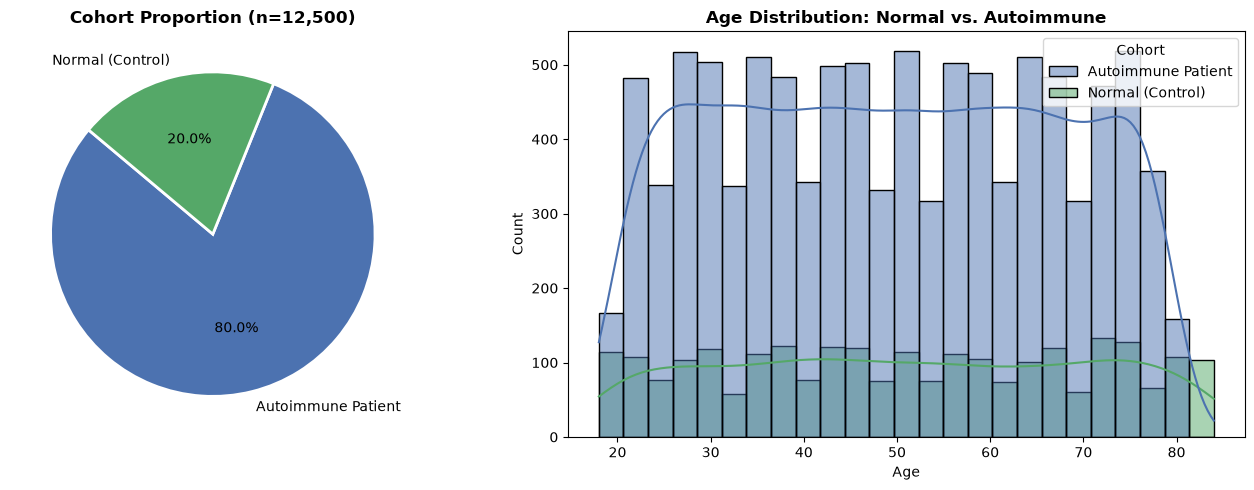

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Donut chart of cohorts
cohort_counts = df["Cohort"].value_counts()
axes[0].pie(
    cohort_counts,
    labels=cohort_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4c72b0", "#55a868"],
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
axes[0].set_title("Cohort Proportion (n=12,500)", fontweight="bold")
# Age distribution by cohort
sns.histplot(
    data=df,
    x="Age",
    hue="Cohort",
    kde=True,
    ax=axes[1],
    palette=["#4c72b0", "#55a868"],
    bins=25,
)
axes[1].set_title("Age Distribution: Normal vs. Autoimmune", fontweight="bold")
plt.tight_layout()
plt.show()

### VISUALIZATION 2: Biomarkers & Inflammatory Indices

/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/118636279.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/118636279.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/118636279.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/118636279.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will 

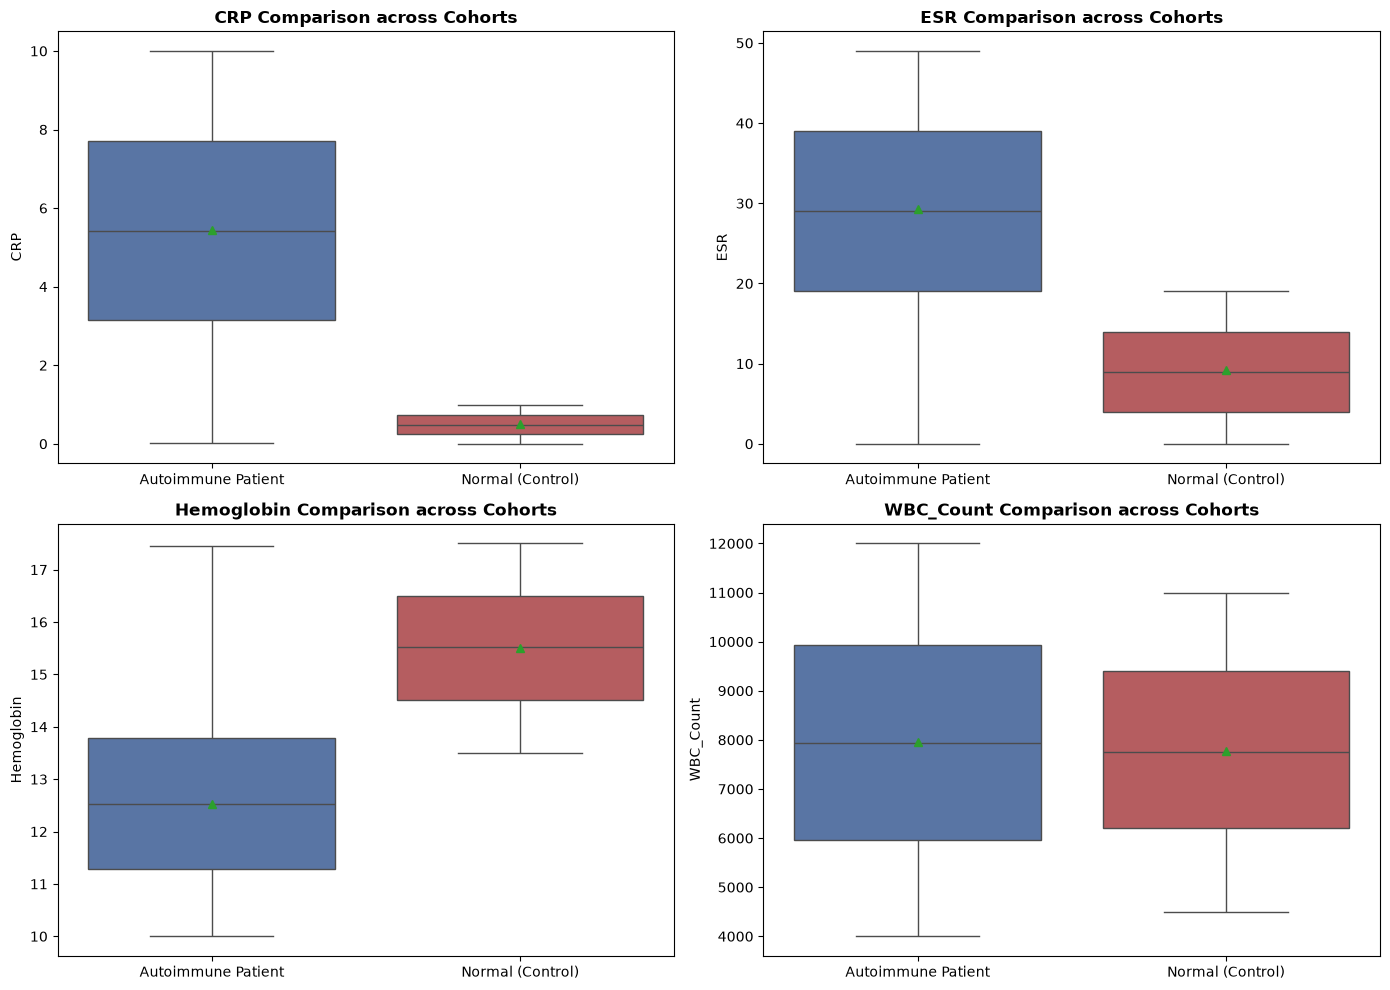

In [14]:
key_metrics = ["CRP", "ESR", "Hemoglobin", "WBC_Count"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, metric in zip(axes.flatten(), key_metrics):
    sns.boxplot(
        data=df,
        x="Cohort",
        y=metric,
        ax=ax,
        palette=["#4c72b0", "#c44e52"],
        showmeans=True,
    )
    ax.set_title(f"{metric} Comparison across Cohorts", fontweight="bold")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### VISUALIZATION 3: Clinical Symptoms in Autoimmune Patients

/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/3119302310.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=symptom_pct.values, y=symptom_pct.index, palette="mako")


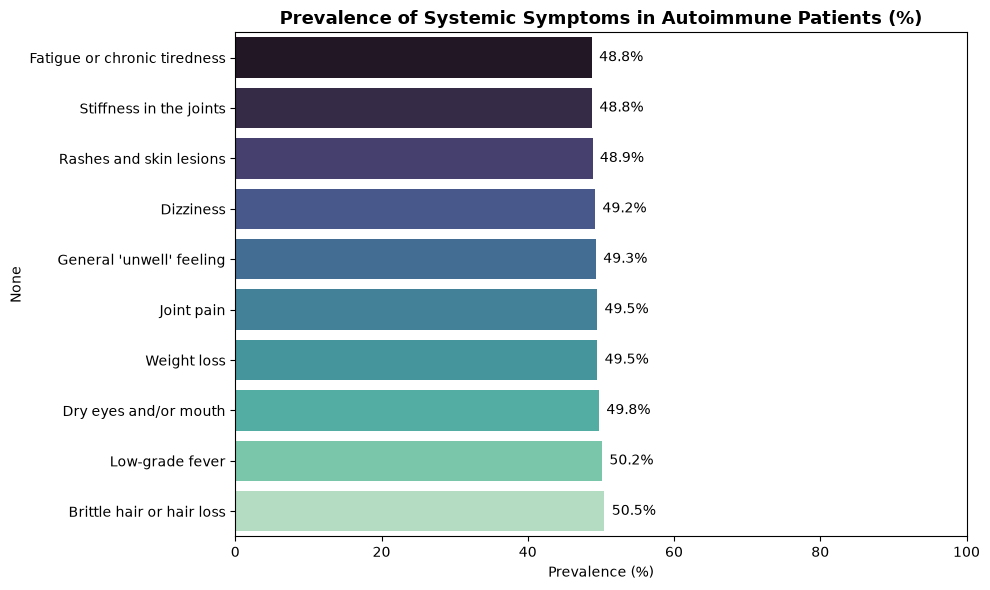

In [15]:
autoimmune_df = df[df["Cohort"] == "Autoimmune Patient"]
symptom_pct = (autoimmune_df[symptom_cols].mean() * 100).sort_values(
    ascending=True
)
plt.figure(figsize=(10, 6))
sns.barplot(x=symptom_pct.values, y=symptom_pct.index, palette="mako")
plt.title(
    "Prevalence of Systemic Symptoms in Autoimmune Patients (%)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Prevalence (%)")
plt.xlim(0, 100)
for idx, val in enumerate(symptom_pct.values):
    plt.text(val + 1, idx, f"{val:.1f}%", va="center", fontsize=10)
plt.tight_layout()
plt.show()

### VISUALIZATION 4: Top 20 Most Prevalent Autoimmune Diagnoses

/var/folders/yc/wyy6bsrj0f15kvgqrf8wllg00000gn/T/ipykernel_44391/3253304838.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_diagnoses.values, y=top_diagnoses.index, palette="viridis")


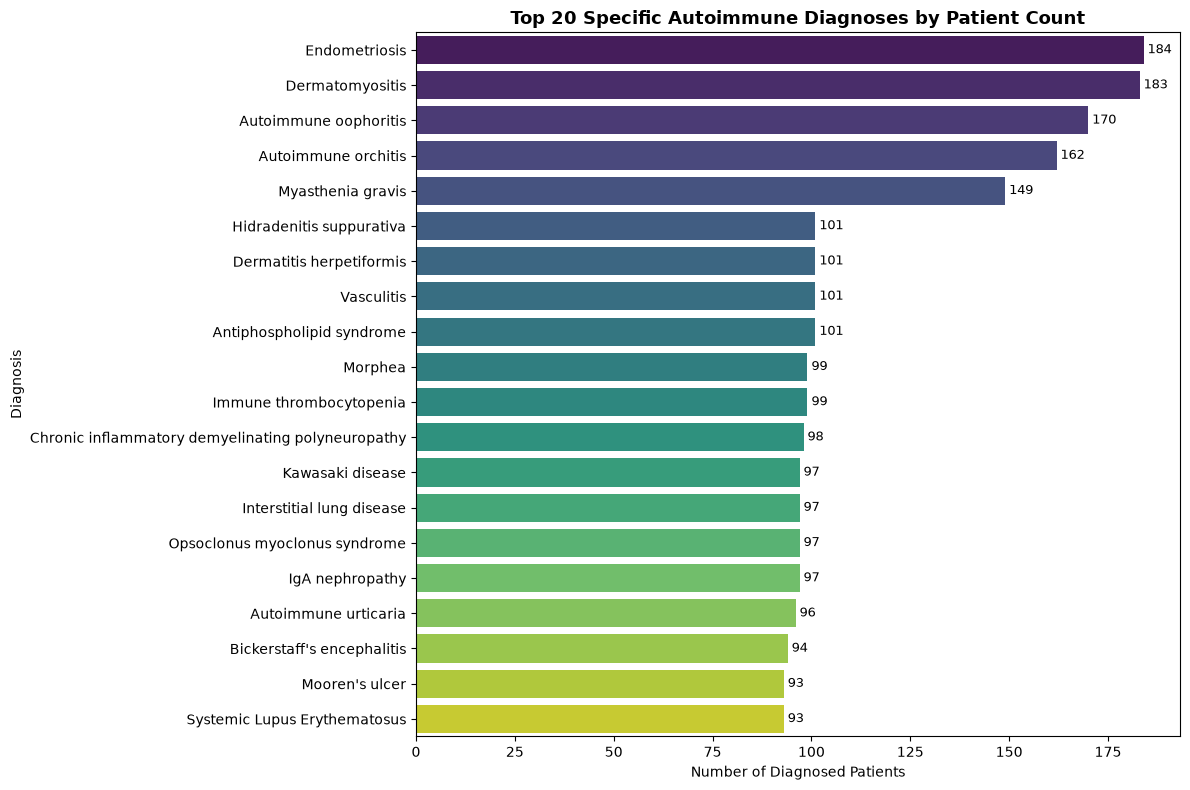

In [16]:
top_diagnoses = autoimmune_df["Diagnosis"].value_counts().head(20)
plt.figure(figsize=(12, 8))
sns.barplot(x=top_diagnoses.values, y=top_diagnoses.index, palette="viridis")
plt.title(
    "Top 20 Specific Autoimmune Diagnoses by Patient Count",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Number of Diagnosed Patients")
plt.ylabel("Diagnosis")
for idx, val in enumerate(top_diagnoses.values):
    plt.text(val + 1, idx, f"{val}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### VISUALIZATION 5: Correlation Matrix of Key Diagnostic Markers

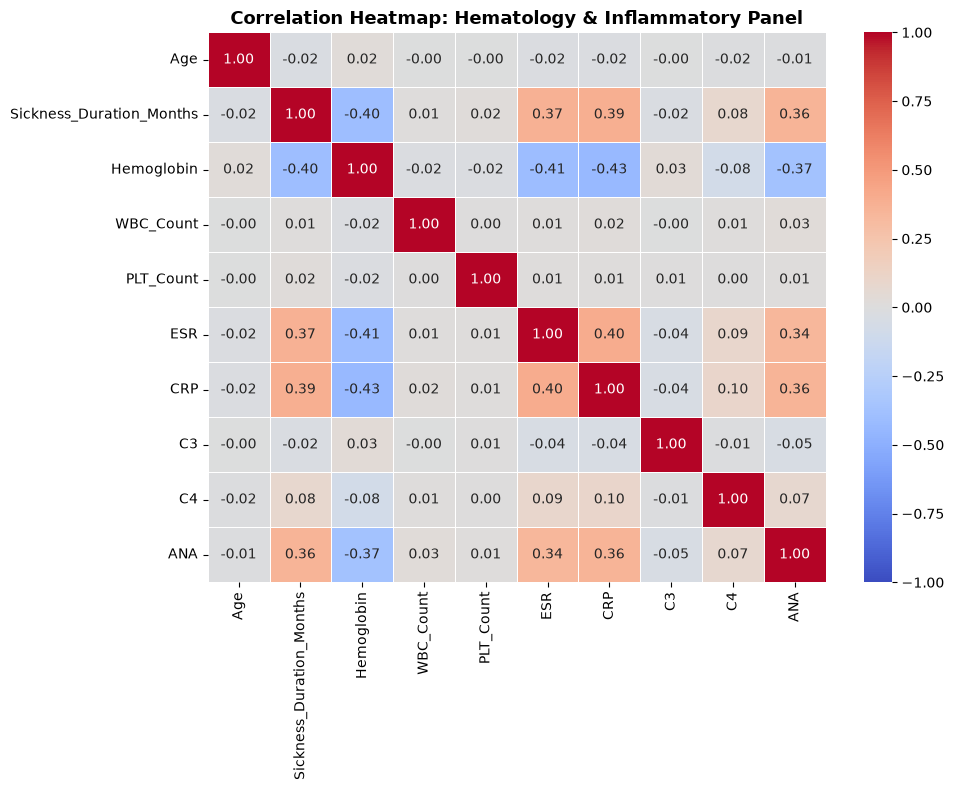

In [17]:
corr_features = [
    "Age",
    "Sickness_Duration_Months",
    "Hemoglobin",
    "WBC_Count",
    "PLT_Count",
    "ESR",
    "CRP",
    "C3",
    "C4",
    "ANA",
]
corr_matrix = df_clean[corr_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    "Correlation Heatmap: Hematology & Inflammatory Panel",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()